In [1]:
import os
import re
import string
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Download NLTK stopwords resource
nltk.download('stopwords', quiet=True)

# Setup plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 6)

# Step 1: Load Dataset

In [2]:
DATA_DIR = "Adversarial BEC Email Dataset"
clean_path = os.path.join(DATA_DIR, "synthetic_emails.csv")
poisoned_path = os.path.join(DATA_DIR, "synthetic_emails_poisoned.csv")

df_clean = pd.read_csv("synthetic_emails.csv")
df_poisoned = pd.read_csv("synthetic_emails_poisoned.csv")

print("Clean shape:", df_clean.shape)
print("Poisoned shape:", df_poisoned.shape)

Clean shape: (4211, 3)
Poisoned shape: (4211, 3)


# Step 2: Data Filtering

In [3]:
text_clean_series = df_clean['subject'].fillna('') + " " + df_clean['body'].fillna('')
text_poisoned_series = df_poisoned['subject'].fillna('') + " " + df_poisoned['body'].fillna('')

is_different = text_clean_series != text_poisoned_series

clean_filtered_text = text_clean_series[is_different]
poisoned_filtered_text = text_poisoned_series[is_different]

print("Clean filtered length:", len(clean_filtered_text))
print("Poisoned filtered length:", len(poisoned_filtered_text))

Clean filtered length: 1187
Poisoned filtered length: 1187


# Step 3: Create Target Labels

In [4]:
clean_filtered = pd.DataFrame({
    'text': clean_filtered_text,
    'label': 0
})

poisoned_filtered = pd.DataFrame({
    'text': poisoned_filtered_text,
    'label': 1
})

# Step 4: Combine Dataset

In [5]:
df_all = pd.concat([clean_filtered, poisoned_filtered], ignore_index=True)

print("Combined dataset shape:", df_all.shape)
print("Label counts:\n", df_all['label'].value_counts())

Combined dataset shape: (2374, 2)
Label counts:
 label
0    1187
1    1187
Name: count, dtype: int64


# Step 5: Text Preprocessing

In [6]:
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # 3. Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 4. Remove stopwords
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]
    
    return " ".join(filtered_words)

df_all['text_preprocessed'] = df_all['text'].apply(preprocess_text)

print("Original text example:")
print(df_all.loc[0, 'text'][:150])
print("\nPreprocessed text example:")
print(df_all.loc[0, 'text_preprocessed'][:150])

Original text example:
Project Alpha Funds Release – Mandatory. The $38,648 retainage for Project Alpha is to be released. I’ve attached the waiver for your immediate proces

Preprocessed text example:
project alpha funds release – mandatory 38648 retainage project alpha released i’ve attached waiver immediate processing open discussion simply execut


# Step 6: TF-IDF Vectorization

In [7]:
vectorizer = TfidfVectorizer(sublinear_tf=True)
X = vectorizer.fit_transform(df_all['text_preprocessed']) 
y = df_all['label']

print("X shape:", X.shape)

X shape: (2374, 13083)


# Step 7: Train/Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1899, 13083)
X_test shape: (475, 13083)


# Step 8: Model Training

In [9]:
model = MultinomialNB(alpha=0.5)
model.fit(X_train, y_train) 

,alpha,0.5
,force_alpha,True
,fit_prior,True
,class_prior,None


# Step 9: Evaluation

=== Metrics ===
Accuracy : 0.8042
Precision: 0.9737
Recall   : 0.6245
F1-score : 0.7609

=== Classification Report ===
              precision    recall  f1-score   support

   Clean (0)       0.72      0.98      0.83       238
Poisoned (1)       0.97      0.62      0.76       237

    accuracy                           0.80       475
   macro avg       0.85      0.80      0.80       475
weighted avg       0.85      0.80      0.80       475



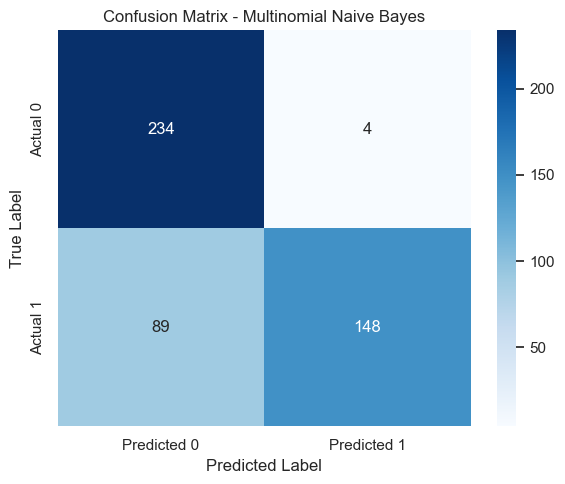

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

print("=== Metrics ===")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Clean (0)', 'Poisoned (1)']))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted 0', 'Predicted 1'], 
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show() 